# Fitting a single frame

Here we extract a normalized hologram of a colloidal sphere from unnormalized
experimental microscopy data, find the sphere, and fit its hologram to the
Lorenz-Mie theory. Along the way we meet the steps that a **Frame** carries out
for you.

In [1]:
%matplotlib inline
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd

from pylorenzmie.analysis import Feature, Frame, Hologram, Localizer
from pylorenzmie.theory import Instrument
from pylorenzmie.utilities import Normalizer

pd.set_option('display.precision', 3)
plt.rcParams['figure.dpi'] = 72

## Extracting a normalized frame

To normalize an image we need the raw data, a background image recorded without
the sample, and the formula

$$\frac{I_{\rm image} - {\rm dc}}{I_{\rm background} - {\rm dc}},$$

where $I$ is the measured intensity and dc is the camera's dark count, the value
that it reports with no light. Both images are PNG files. OpenCV reads them as
integer arrays, so we convert them to floating point first.

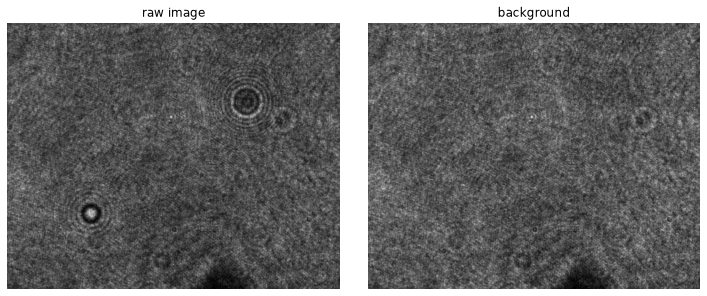

In [2]:
image = cv2.imread('sample.png', cv2.IMREAD_GRAYSCALE).astype(float)
background = cv2.imread('background.png', cv2.IMREAD_GRAYSCALE).astype(float)
dark_count = 13        # the camera's dark count

fig, axes = plt.subplots(ncols=2, figsize=(10, 4), constrained_layout=True)
for ax, data, title in zip(axes, (image, background), ('raw image', 'background')):
    ax.imshow(data, cmap='gray')
    ax.set_title(title)
    ax.axis('off')
plt.show()

The raw image has an average value of about 78 counts, far from 1. A
**Normalizer** divides an image by a background. Its `'reference'` method divides
by a recorded background image, here with the dark count subtracted from both.

mean 1.003


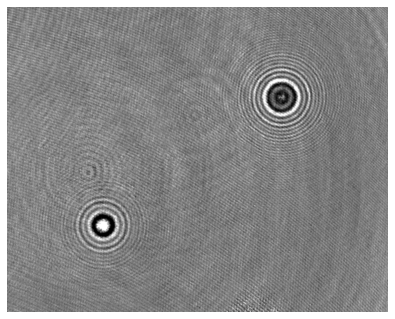

In [3]:
normalizer = Normalizer(method='reference', reference=background - dark_count)
norm = normalizer(image - dark_count)

print('mean', norm.mean().round(3))
fig, ax = plt.subplots(figsize=(7, 5.5))
ax.imshow(norm, cmap='gray', vmin=0.4, vmax=1.6)
ax.axis('off')
plt.show()

The mean of a normalized frame should be close to 1. That is essential for
least-squares fitting and for the detection algorithm. If you have no
background image, `Normalizer(method='median')` divides by the median of the image,
and `Normalizer(method='filter')` estimates the background with a large median
filter.

## Finding the holographic features

A **Localizer** finds the features. It enhances the ring-like patterns of
holograms with a circle transform and then locates the centers of the bright
spots with `trackpy`. It returns a table with the center of each feature and a
bounding box around it. Detection can be tuned to a specific image. The most
important parameter is the nominal `diameter` of a feature, in pixels.

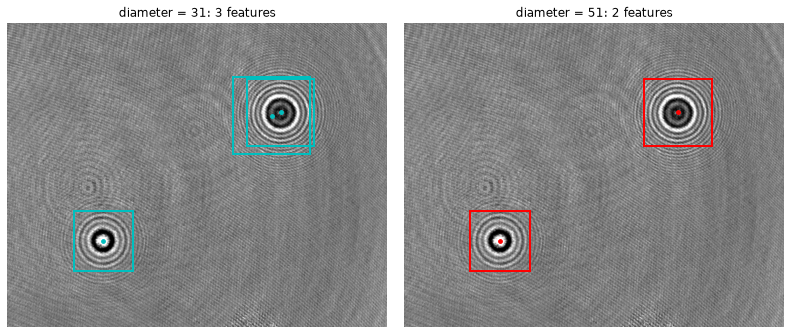

In [4]:
def show(norm, features, ax, **style):
    ax.imshow(norm, cmap='gray', vmin=0.4, vmax=1.6)
    for bbox in features.bbox:
        ax.add_patch(Rectangle(*bbox, fill=False, lw=2, **style))
    ax.scatter(features.x_p, features.y_p, c=style['ec'], s=14)
    ax.axis('off')


fig, axes = plt.subplots(ncols=2, figsize=(11, 4.5), constrained_layout=True)
for ax, diameter, color in zip(axes, (31, 51), ('c', 'r')):
    features = Localizer(diameter=diameter).localize(norm)
    show(norm, features, ax, ec=color)
    ax.set_title(f'diameter = {diameter}: {len(features)} features')
plt.show()

There are two spheres in this frame. With the default diameter of 31 pixels the
upper-right sphere is found twice, once at its center and once at an
offset. A diameter of 51 pixels removes the duplicate. We keep that value. (When
the candidates need more care, `localize()` passes extra keyword arguments such as `minmass` on to
`trackpy.locate`.)

In [5]:
localizer = Localizer(diameter=51)
features = localizer.localize(norm)
features

,x_p,y_p,bbox
0,922.472,300.113,"((809, 187), 228, 228)"
1,321.324,734.791,"((222, 635), 200, 200)"


## The bounding box

Each bounding box is `((x0, y0), width, height)`. Its size is set by `nfringes`,
the number of interference fringes, a bright and a dark ring each, that it
encloses. The box is clipped to the image. Larger boxes contain more of the
signal, and give the fit more information, but also more of the neighbors' and
of the noise.

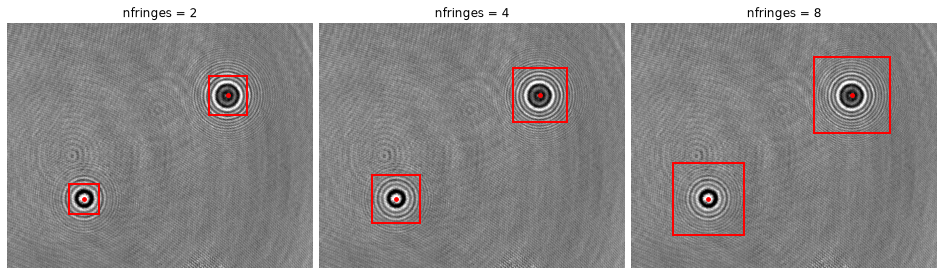

In [6]:
fig, axes = plt.subplots(ncols=3, figsize=(13, 4), constrained_layout=True)
for ax, nfringes in zip(axes, (2, 4, 8)):
    found = localizer.localize(norm, nfringes=nfringes)
    show(norm, found, ax, ec='r')
    ax.set_title(f'nfringes = {nfringes}')
plt.show()

## Fitting a feature

We crop the frame to the bounding box of one of the features. A **Hologram**
keeps track of the pixel coordinates of the full frame, so the cropped
hologram knows where it came from. We start with the sphere at the lower left.

crop of (200, 200) pixels with its corner at (222.0, 635.0)


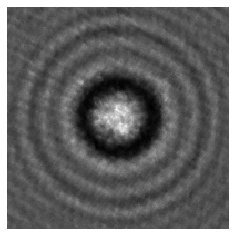

In [7]:
def crop_feature(index):
    (x0, y0), width, height = features.bbox.iloc[index]
    return Hologram(norm)[y0:y0 + height, x0:x0 + width]


crop = crop_feature(1)
print('crop of', crop.shape, 'pixels with its corner at', crop.corner)

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(crop.data, cmap='gray', interpolation='none')
ax.axis('off')
plt.show()

A **Feature** pairs the crop with a model of the instrument and the sphere.
We tell it about the microscope. The sphere's properties are unknown, so we
ask the feature's estimator to search for starting values, and then ask the
optimizer to refine them. The search is random, so we fix its seed to get the
same answer every time.

In [8]:
instrument = Instrument(wavelength=0.447, magnification=0.048, n_m=1.34)

feature = Feature(crop)
feature.model.instrument = instrument
feature.mask.fraction = 0.2
feature.estimator.seed = 0

estimate = feature.estimate()
print('estimate:', estimate[['x_p', 'y_p', 'z_p', 'a_p', 'n_p']].round(3).to_dict())

result = feature.optimize()
result[['x_p', 'dx_p', 'y_p', 'dy_p', 'z_p', 'dz_p', 'a_p', 'da_p', 'n_p', 'dn_p', 'redchi']]

estimate: {'x_p': 321.5, 'y_p': 734.5, 'z_p': 230.912, 'a_p': 0.871, 'n_p': 1.442}


x_p       321.721
dx_p        0.043
y_p       733.477
dy_p        0.042
z_p       230.176
dz_p        0.334
a_p         0.858
da_p        0.002
n_p         1.443
dn_p        0.001
redchi      5.484
dtype: object

The fit reproduces the structure of the recorded hologram. The residuals show
what the model could not explain.

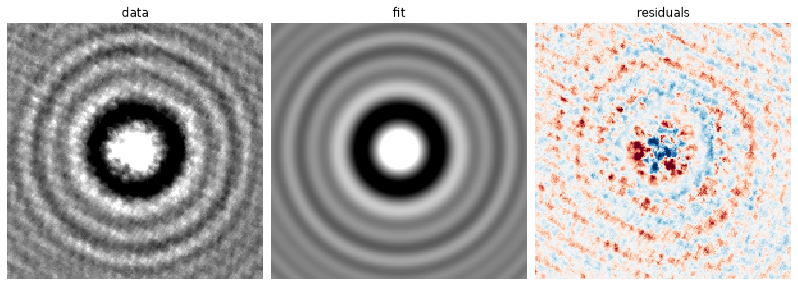

In [9]:
def present(feature):
    fig, axes = plt.subplots(ncols=3, figsize=(11, 3.8), constrained_layout=True)
    style = dict(cmap='gray', vmin=0.4, vmax=1.6, interpolation='none')
    axes[0].imshow(feature.data, **style)
    axes[0].set_title('data')
    axes[1].imshow(feature.predicted(), **style)
    axes[1].set_title('fit')
    axes[2].imshow(feature.residuals(), cmap='RdBu', vmin=-0.5, vmax=0.5,
                   interpolation='none')
    axes[2].set_title('residuals')
    for ax in axes:
        ax.axis('off')
    plt.show()


present(feature)

## A harder feature

The sphere at the upper right is harder. The estimator searches the whole range
of radii, indices and depths that it is allowed, from air bubbles to
high-index particles and from the focal plane to far above it, using a small
random sample of the pixels. Several very different particles can produce
similar fringes, and the search can settle on the wrong one.

z_p       370.762
a_p           0.6
n_p         2.752
redchi     19.136


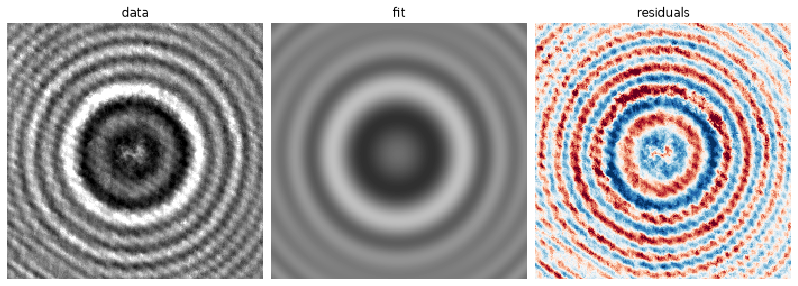

In [10]:
hard = Feature(crop_feature(0))
hard.model.instrument = instrument
hard.mask.fraction = 0.2
hard.estimator.seed = 1

hard.estimate()
result = hard.optimize()
print(result[['z_p', 'a_p', 'n_p', 'redchi']].round(3).to_string())
present(hard)

The fit is poor: the reduced chi-squared is far above 1, the residuals show
structure, and the refractive index of 2.7 is higher than that of
almost any material that makes colloidal spheres. With a different seed the
search ends elsewhere. There are two remedies, and they work best together.

1. **Prior knowledge.** We know that this sample contains polymer or silica
   spheres in water, with radii of order 1 µm, a few hundred pixels
   from the focal plane. Restricting the search to those ranges excludes the
   wrong solutions.
2. **A robust loss.** Pixels that the model cannot explain, such as dust and
   the fringes of other particles, then have less influence on the fit.

z_p       227.252
a_p         1.059
n_p         1.572
redchi      1.342


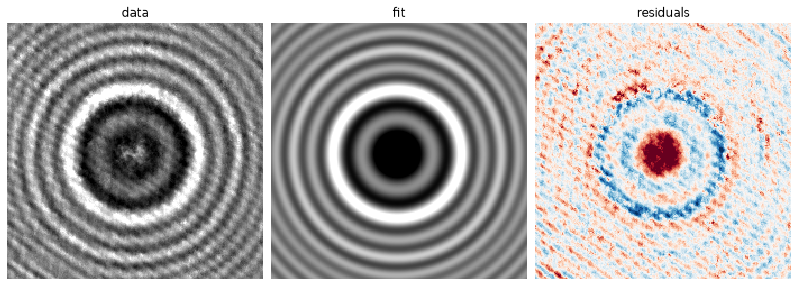

In [11]:
hard = Feature(crop_feature(0))
hard.model.instrument = instrument
hard.mask.fraction = 0.2
hard.estimator.seed = 0
hard.estimator.bounds = {'z_p': (100., 350.),    # [pixels]
                         'a_p': (0.5, 2.),       # [um]
                         'n_p': (1.3, 1.8)}
hard.optimizer.robust = True

hard.estimate()
result = hard.optimize()
print(result[['z_p', 'a_p', 'n_p', 'redchi']].round(3).to_string())
present(hard)

The reduced chi-squared is close to 1, the residuals are mostly noise, and the
refractive index of about 1.56 is typical of polystyrene. (The reduced
chi-squared of a robust fit is computed from the robust cost, so it is
not strictly comparable with the one from least squares.)

## Doing it all at once

A **Frame** does everything above: it detects the features, crops each one,
estimates starting values and fits it. We give it the instrument and the
localizer that we tuned. Each feature has its own estimator and optimizer, so
after `detect()` we can apply what we know to all of them, and then run the
remaining steps.

In [12]:
frame = Frame(instrument=instrument, localizer=localizer)
frame.data = norm
frame.detect()
for feature in frame.features:
    feature.estimator.seed = 0
    feature.estimator.bounds = {'z_p': (100., 350.),
                                'a_p': (0.5, 2.),
                                'n_p': (1.3, 1.8)}
    feature.optimizer.robust = True
frame.estimate()
frame.optimize()
frame.results[['x_p', 'y_p', 'z_p', 'a_p', 'n_p', 'dz_p', 'da_p', 'dn_p', 'redchi']]

,x_p,y_p,z_p,a_p,n_p,dz_p,da_p,dn_p,redchi
0,920.860,303.404,226.956,1.058,1.571,0.218,0.003,1.263e-03,1.336
1,321.862,733.404,231.313,0.881,1.443,0.495,0.004,9.425e-04,1.169


`frame.analyze(norm)` runs the same three steps without the extra knowledge, which
is a good place to start with a new kind of sample.